<a href="https://colab.research.google.com/github/davide-ario/BNN/blob/main/BNN_returns_to_education_card.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Returns to schooling with rich controls: Card (1995) data

This notebook repeats the analysis of
[`BNN_returns_to_education.ipynb`](BNN_returns_to_education.ipynb) on the
data of Card (1995), *Using geographical variation in college proximity to
estimate the return to schooling*. The CPS example had only age, gender and
region as controls. Here we have:

* family background (parents' education, family structure at age 14);
* **ability proxies**: an IQ score and a test of "knowledge of the world of
  work" (KWW);
* an **instrument**, whether the respondent grew up near a four-year
  college, which Card used to estimate a causal return.

This lets us ask three questions:

1. Is the marginal return to a year of schooling constant (Mincer),
   diminishing, or step-shaped?
2. How much of the estimated return is really ability (ability bias), and
   does a flexible model of the controls change that?
3. Does the nested BNN fit better than a standard BNN, and how stable are the
   results across runs?

**Data**: National Longitudinal Survey of Young Men, 3,010 men aged 24–34 in
1976 (`Ecdat::Schooling`, the extract used in Verbeek's *A Guide to Modern
Econometrics*).

## Setup

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q "pymc>=6.4" "arviz>=1.0" linearmodels
    !wget -q https://raw.githubusercontent.com/davide-ario/BNN/main/bnn_models.py

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

import bnn_models as bm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
SEED = 0
print(f"PyMC v{pm.__version__}")

PyMC v6.4.0


## 1. Data

In [3]:
URL = ("https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/"
       "master/csv/Ecdat/Schooling.csv")
df = pd.read_csv(URL, index_col=0)
for col in df.columns:  # yes/no indicators -> 1/0
    values = set(df[col].dropna().unique())
    if values <= {"yes", "no"}:
        df[col] = df[col].map({"yes": 1.0, "no": 0.0})
df["exp2"] = df["exp76"] ** 2
df["age2"] = df["age76"] ** 2

CONTROLS = ["exp76", "black", "south76", "smsa76", "south66", "smsa66",
            "daded", "momed", "nodaded", "momdad14", "sinmom14", "step14"]
ABILITY = ["iqscore", "kww"]
df[["lwage76", "ed76"] + CONTROLS + ABILITY + ["nearc4"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
lwage76,3010.0,6.26,0.44,4.61,5.98,6.29,6.56,7.78
ed76,3010.0,13.26,2.68,1.00,12.00,13.00,16.00,18.00
exp76,3010.0,8.86,4.14,0.00,6.00,8.00,11.00,23.00
black,3010.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
south76,3010.0,0.40,0.49,0.00,0.00,0.00,1.00,1.00
smsa76,3010.0,0.71,0.45,0.00,0.00,1.00,1.00,1.00
south66,3010.0,0.41,0.49,0.00,0.00,0.00,1.00,1.00
smsa66,3010.0,0.65,0.48,0.00,0.00,1.00,1.00,1.00
daded,3010.0,9.99,3.27,0.00,8.00,9.94,12.00,18.00
momed,3010.0,10.34,2.99,0.00,9.00,11.00,12.00,18.00


Experience is potential experience (age − education − 6). Parents'
education is imputed at the mean when missing. The flags `nodaded` and
`nomomed` mark the imputed cases; they are identical in this extract, so we
keep only `nodaded`. IQ is missing for about a third of the sample,
so the ability analysis (section 4) uses the 2,040 men with both scores.

Unlike the CPS, schooling here is recorded in actual years. Very few men
have fewer than 8 years, so we pool them into a single "8 or fewer"
category whenever we estimate a separate effect per year.

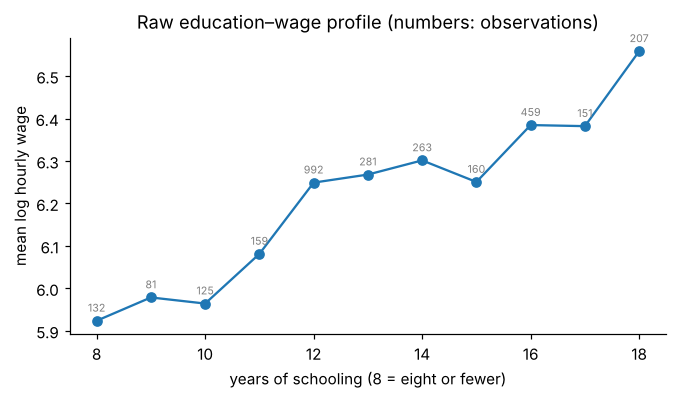

In [4]:
df["ed_level"] = df["ed76"].clip(lower=8)
levels = np.arange(8, 19)
summary = df.groupby("ed_level").agg(n=("lwage76", "size"),
                                     mean_log_wage=("lwage76", "mean"))
summary["raw step"] = summary["mean_log_wage"].diff()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(summary.index, summary["mean_log_wage"], "o-")
for x, n in summary["n"].items():
    ax.annotate(f"{n}", (x, summary.loc[x, "mean_log_wage"]), fontsize=7,
                textcoords="offset points", xytext=(0, 6), ha="center", color="grey")
ax.set(xlabel="years of schooling (8 = eight or fewer)", ylabel="mean log hourly wage",
       title="Raw education–wage profile (numbers: observations)")
plt.show()

## 2. Benchmarks

* **OLS Mincer**: one return to schooling, with experience, experience²,
  race, region and urban indicators (Card's specification) plus family
  background.
* **OLS education dummies**: one dummy per year of schooling, same controls.
* **IV (2SLS)**: Card's strategy. Schooling is instrumented with living
  near a four-year college; experience and its square are instrumented with
  age and age², since potential experience is mechanically related to
  schooling.

In [5]:
rhs = " + ".join(["exp2"] + CONTROLS)
mincer = smf.ols(f"lwage76 ~ ed76 + {rhs}", df).fit(cov_type="HC1")
dummies = smf.ols(f"lwage76 ~ C(ed_level) + {rhs}", df).fit(cov_type="HC1")

exog = " + ".join(c for c in CONTROLS if c != "exp76")
iv = IV2SLS.from_formula(
    f"lwage76 ~ 1 + {exog} + [ed76 + exp76 + exp2 ~ nearc4 + age76 + age2]", df
).fit(cov_type="robust")

benchmarks = pd.DataFrame({
    "return per year": [mincer.params["ed76"], iv.params["ed76"]],
    "s.e.": [mincer.bse["ed76"], iv.std_errors["ed76"]],
}, index=["OLS Mincer", "IV (near 4-year college)"])
benchmarks.round(4)

,return per year,s.e.
OLS Mincer,0.0716,0.0038
IV (near 4-year college),0.1234,0.0503


The IV estimate is much larger than OLS, as in Card (1995), but also much
less precise: its standard error is more than ten times larger.

In [6]:
def dummy_steps(fit):
    """Log-wage step from each year of schooling to the next, with 90% CI."""
    rows = []
    for k in range(1, len(levels)):
        w = pd.Series(0.0, index=fit.params.index)
        w[f"C(ed_level)[T.{levels[k]}]"] = 1.0
        if k > 1:
            w[f"C(ed_level)[T.{levels[k - 1]}]"] = -1.0
        est = float(w @ fit.params)
        sd = float(np.sqrt(w @ fit.cov_params() @ w))
        rows.append((levels[k], est, est - 1.645 * sd, est + 1.645 * sd))
    return pd.DataFrame(rows, columns=["education", "step", "lo", "hi"])


ols_steps = dummy_steps(dummies)

## 3. Bayesian neural network

Inputs: years of schooling plus the 12 controls above. The architecture
and fitting are the same as in the CPS notebook: three ReLU hidden layers of
30 units, and mini-batch ADVI with batches of 100 observations. We hold out
25% of the sample for an out-of-sample comparison.

In [7]:
FEATURES = ["ed76"] + CONTROLS
train, test = train_test_split(df, test_size=0.25, random_state=SEED)

x_mean = train[FEATURES].mean().to_numpy()
x_sd = train[FEATURES].std().to_numpy()
y_mean, y_sd = train["lwage76"].mean(), train["lwage76"].std()


def scale(d):
    return (d[FEATURES].to_numpy(float) - x_mean) / x_sd


ys_train = ((train["lwage76"] - y_mean) / y_sd).to_numpy()
idata_bnn, hist_bnn = bm.fit_advi(bm.build_bnn, scale(train), ys_train,
                                  n_iter=60_000, batch_size=100, seed=SEED)

ols_train = smf.ols(f"lwage76 ~ ed76 + {rhs}", train).fit()
dum_train = smf.ols(f"lwage76 ~ C(ed_level) + {rhs}", train).fit()
mu_test = bm.predict_mu(bm.build_bnn, idata_bnn, scale(test))
pd.Series({
    "OLS Mincer": r2_score(test["lwage76"], ols_train.predict(test)),
    "OLS education dummies": r2_score(test["lwage76"], dum_train.predict(test)),
    "BNN": r2_score(test["lwage76"], mu_test.mean(0) * y_sd + y_mean),
}, name="test R²").round(4).to_frame()

,test R²
OLS Mincer,0.2476
OLS education dummies,0.2505
BNN,0.2371


### Marginal return to each year of schooling

As in the CPS notebook, we set every man's schooling to each level in turn,
keep his other characteristics, average the predicted log wage, and take
differences between consecutive years. Because the sample is small, we
average over the whole data set rather than a subsample.

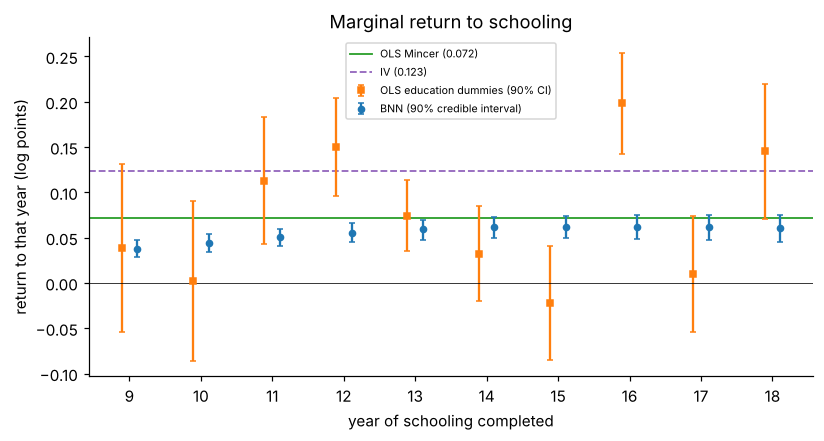

In [8]:
def bnn_steps(builder, idata, ref=df):
    """Posterior draws of the log-wage step from each year to the next."""
    stacked = pd.concat([ref.assign(ed76=float(e)) for e in levels])
    mu = bm.predict_mu(builder, idata, scale(stacked))
    profile = mu.reshape(mu.shape[0], len(levels), len(ref)).mean(axis=2) * y_sd
    return np.diff(profile, axis=1)


def summarise(draws):
    lo, med, hi = np.percentile(draws, [5, 50, 95], axis=0)
    return pd.DataFrame({"education": levels[1:], "step": med, "lo": lo, "hi": hi})


bnn_table = summarise(bnn_steps(bm.build_bnn, idata_bnn))


def plot_steps(ax, tables):
    b, b_iv = mincer.params["ed76"], iv.params["ed76"]
    ax.axhline(b, color="C2", lw=1.2, label=f"OLS Mincer ({b:.3f})")
    ax.axhline(b_iv, color="C4", lw=1.2, ls="--", label=f"IV ({b_iv:.3f})")
    n = len(tables)
    for i, (label, t, style) in enumerate(tables):
        ax.errorbar(t["education"] + (i - (n - 1) / 2) * 0.22, t["step"],
                    yerr=[t["step"] - t["lo"], t["hi"] - t["step"]],
                    capsize=2, ms=4, label=label, **style)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="year of schooling completed", xticks=levels[1:])
    ax.legend(fontsize=7)


fig, ax = plt.subplots(figsize=(8.5, 4))
plot_steps(ax, [("OLS education dummies (90% CI)", ols_steps, dict(fmt="s", color="C1")),
                ("BNN (90% credible interval)", bnn_table, dict(fmt="o", color="C0"))])
ax.set(ylabel="return to that year (log points)", title="Marginal return to schooling")
plt.show()

## 4. Ability bias

If more able people both study longer and earn more, part of the OLS
return reflects ability. We compare the return to schooling with and
without the IQ and KWW scores, on the same subsample of 2,040 men, for:

* OLS Mincer;
* the **partially linear BNN**,
  $\log w = \alpha + \beta\,\text{educ} + f(\text{controls}) + \varepsilon$,
  where the network models all controls flexibly.

If the drop in $\beta$ were an artefact of the linear way OLS includes the
controls, the partially linear BNN would show a different drop.

In [9]:
ab = df.dropna(subset=ABILITY).copy()
rows = {}
for label, extra in [("without ability", []), ("with IQ + KWW", ABILITY)]:
    ols_fit = smf.ols(f"lwage76 ~ ed76 + {' + '.join(['exp2'] + CONTROLS + extra)}",
                      ab).fit(cov_type="HC1")
    cols = ["ed76"] + CONTROLS + extra
    Xa = ab[cols].to_numpy(float)
    m_, s_ = Xa.mean(0), Xa.std(0)
    ya_m, ya_s = ab["lwage76"].mean(), ab["lwage76"].std()
    idata_pl, _ = bm.fit_advi(bm.build_partially_linear_bnn, (Xa - m_) / s_,
                              ((ab["lwage76"] - ya_m) / ya_s).to_numpy(),
                              n_iter=60_000, batch_size=100, seed=SEED,
                              linear_cols=(0,))
    beta = idata_pl.posterior["beta"].values.reshape(-1) * ya_s / s_[0]
    rows[("OLS Mincer", label)] = (ols_fit.params["ed76"], ols_fit.bse["ed76"])
    rows[("Partially linear BNN", label)] = (beta.mean(), beta.std())

ability = pd.DataFrame(rows, index=["return per year", "s.e. / posterior sd"]).T
ability

,,return per year,s.e. / posterior sd
OLS Mincer,without ability,0.073681,0.004965
Partially linear BNN,without ability,0.056497,0.003967
OLS Mincer,with IQ + KWW,0.057681,0.005829
Partially linear BNN,with IQ + KWW,0.042927,0.003257


### Cross-check: double machine learning

The partially linear BNN estimates $\beta$ and the network $f$ jointly. If
$f$ is over- or under-regularised, and the controls are correlated with
schooling (parents' education predicts their son's schooling), part of the
education effect can be wrongly attributed to $f$, or the reverse.

**Double machine learning** (Chernozhukov et al., 2018) protects against
this bias. With 5-fold cross-fitting, a machine-learning model predicts both
log wage and schooling from the controls; $\beta$ is then the OLS slope of
the wage residuals on the schooling residuals. We use a random forest and
gradient boosting as the ML models.

In [10]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict


def dml_beta(data, controls, model):
    """Cross-fitted partialling-out estimate of the return to schooling."""
    X = data[controls].to_numpy(float)
    folds = KFold(5, shuffle=True, random_state=SEED)
    r_y = data["lwage76"] - cross_val_predict(model, X, data["lwage76"], cv=folds)
    r_e = data["ed76"] - cross_val_predict(model, X, data["ed76"], cv=folds)
    fit = smf.ols("r_y ~ r_e - 1", pd.DataFrame({"r_y": r_y, "r_e": r_e})).fit(cov_type="HC1")
    return fit.params["r_e"], fit.bse["r_e"]


ML = {
    "DML, random forest": RandomForestRegressor(300, min_samples_leaf=20,
                                                random_state=SEED, n_jobs=-1),
    "DML, gradient boosting": GradientBoostingRegressor(n_estimators=300, max_depth=3,
                                                        learning_rate=0.05,
                                                        random_state=SEED),
}
for name, model in ML.items():
    for label, extra in [("without ability", []), ("with IQ + KWW", ABILITY)]:
        rows[(name, label)] = dml_beta(ab, CONTROLS + extra, model)

est = pd.DataFrame(rows, index=["beta", "se"]).T["beta"].unstack()
est = est[["without ability", "with IQ + KWW"]]
est["share explained by ability"] = 1 - est["with IQ + KWW"] / est["without ability"]
est.loc[["OLS Mincer", "DML, random forest", "DML, gradient boosting",
         "Partially linear BNN"]].round(4)

,without ability,with IQ + KWW,share explained by ability
OLS Mincer,0.0737,0.0577,0.2171
"DML, random forest",0.0723,0.0557,0.2307
"DML, gradient boosting",0.0709,0.0574,0.1903
Partially linear BNN,0.0565,0.0429,0.2402


## 5. Robustness: nested BNN and run-to-run variation

Same test as in the CPS notebook: we fit the standard and the nested BNN
with five seeds each, compare test R², and pool the draws across runs to
get intervals that also reflect run-to-run variation.

This cell fits nine more networks and takes several minutes.

In [11]:
SEEDS = [0, 1, 2, 3, 4]
BUILDERS = {"BNN": bm.build_bnn, "Nested BNN": bm.build_nested_bnn}
runs = {name: {} for name in BUILDERS}
runs["BNN"][SEED] = idata_bnn
for name, builder in BUILDERS.items():
    for s in SEEDS:
        if s not in runs[name]:
            runs[name][s], _ = bm.fit_advi(builder, scale(train), ys_train,
                                           n_iter=60_000, batch_size=100, seed=s)

X_test = scale(test)
r2 = pd.DataFrame({
    name: {s: r2_score(test["lwage76"],
                       bm.predict_mu(BUILDERS[name], idata, X_test).mean(0) * y_sd + y_mean)
           for s, idata in runs[name].items()}
    for name in BUILDERS})
r2.index.name = "seed"
r2.loc["mean"] = r2.mean()
r2.loc["sd"] = r2.iloc[:-1].std()
r2.round(4)

,BNN,Nested BNN
seed,,
0,0.2371,0.2305
1,0.2434,0.2148
2,0.2589,0.2600
3,0.2351,0.2008
4,0.2414,0.2512
mean,0.2432,0.2315
sd,0.0094,0.0246


Posterior mean of `model_sel` for each input (0 = ReLU network,
1 = tanh network):

In [12]:
sel = pd.DataFrame(
    {s: idata.posterior["model_sel"].mean(("chain", "draw")).values
     for s, idata in runs["Nested BNN"].items()}, index=FEATURES).T
sel.index.name = "seed"
sel.round(2)

,ed76,exp76,black,south76,smsa76,south66,smsa66,daded,momed,nodaded,momdad14,sinmom14,step14
seed,,,,,,,,,,,,,
0,0.43,0.94,0.12,0.16,0.23,0.75,0.32,0.59,0.82,0.71,0.56,0.74,0.66
1,0.42,0.95,0.13,0.15,0.23,0.72,0.31,0.63,0.83,0.76,0.65,0.76,0.64
2,0.07,0.05,0.25,0.33,0.43,0.87,0.74,0.86,0.85,0.88,0.79,0.87,0.86
3,0.42,0.94,0.13,0.15,0.21,0.72,0.34,0.64,0.80,0.73,0.58,0.78,0.69
4,0.08,0.05,0.28,0.36,0.50,0.90,0.73,0.85,0.87,0.92,0.76,0.88,0.86


BNN, average width of the 90% interval: one run 0.023, five runs pooled 0.024 (1.0x)


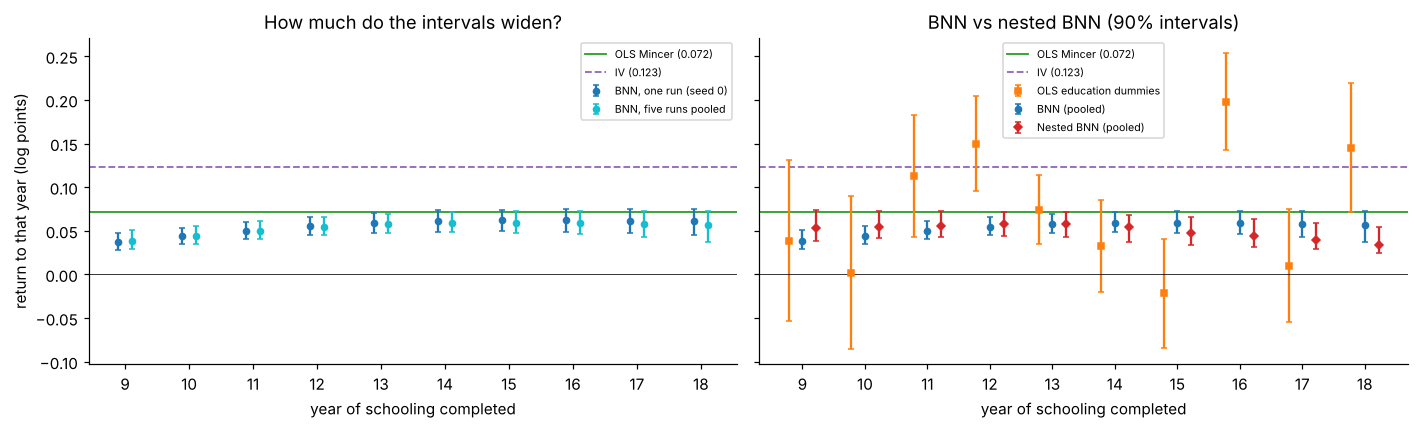

In [13]:
steps = {name: {s: bnn_steps(BUILDERS[name], idata) for s, idata in runs[name].items()}
         for name in BUILDERS}
pooled = {name: summarise(np.concatenate(list(d.values()))) for name, d in steps.items()}
width_single = (bnn_table["hi"] - bnn_table["lo"]).mean()
width_pooled = (pooled["BNN"]["hi"] - pooled["BNN"]["lo"]).mean()
print(f"BNN, average width of the 90% interval: one run {width_single:.3f}, "
      f"five runs pooled {width_pooled:.3f} ({width_pooled / width_single:.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_steps(axes[0], [("BNN, one run (seed 0)", bnn_table, dict(fmt="o", color="C0")),
                     ("BNN, five runs pooled", pooled["BNN"], dict(fmt="o", color="C9"))])
axes[0].set(title="How much do the intervals widen?",
            ylabel="return to that year (log points)")
plot_steps(axes[1], [("OLS education dummies", ols_steps, dict(fmt="s", color="C1")),
                     ("BNN (pooled)", pooled["BNN"], dict(fmt="o", color="C0")),
                     ("Nested BNN (pooled)", pooled["Nested BNN"], dict(fmt="D", color="C3"))])
axes[1].set_title("BNN vs nested BNN (90% intervals)")
plt.tight_layout()
plt.show()

## 6. Takeaways

* **Strong sheepskin effects.** Here schooling is measured in actual years,
  not derived from degrees, so the evidence is cleaner than in the CPS.
  The education dummies show the payoff concentrated in the years that
  complete a degree: about 15 log points for the 12th year (high school),
  20 for the 16th (bachelor's) and 15 for the 18th (graduate degree).
  Most intermediate years (10, 14, 15, 17) add little or nothing. Intervals
  are wide because the sample is small.
* **The BNN does poorly on this data set.** Its out-of-sample R² is below
  OLS (0.243 ± 0.009 across five seeds, against 0.250 for the dummy
  regression). Its education profile is flat at 4–6% per year: it misses
  the degree steps and sits below the Mincer estimate everywhere. With 2,257
  training observations and many inputs correlated with schooling, the
  network spreads part of the education effect over the other inputs.
* **The partially linear BNN is biased, and the cross-check proves it.** It
  puts the return at 5.6%, but three estimators that also model the
  controls flexibly (OLS with all second-order terms, and double machine
  learning with a random forest or gradient boosting) all give 7.1–7.4%,
  the same as OLS. On small samples, double machine learning is the more
  reliable tool for a single coefficient.
* **Ability bias is robust.** Controlling for IQ and the KWW score lowers
  the return by about a fifth (19–24% depending on the method, from about
  7.2% to 5.7% per year in OLS and DML). The partially linear BNN, despite
  its biased level, shows the same proportional drop.
* **IV.** Using college proximity as an instrument gives 12.3% per year,
  larger than OLS as in Card (1995), but with a standard error of 5
  points. It is also a local effect, for men whose schooling responds to
  having a college nearby, so it is not directly comparable with the OLS
  estimates.
* **The nested BNN is worse and unstable.** Its test R² is lower and varies
  three times as much across seeds (0.232 ± 0.025). Its routing has two
  distinct solutions: in two seeds education and experience go to the ReLU
  network, in the other three experience goes to the tanh network. The
  posterior is multimodal, and a single variational fit picks one mode at
  random.
* **Agreement across runs is not correctness.** Pooling five runs barely
  widens the BNN's intervals (1.0x, against 1.8x on the CPS). Yet the
  cross-check shows its estimates are biased: the runs agree with each
  other but are all wrong in the same way.

**Overall**, BNNs were useful on the large CPS sample (61,000 observations,
few inputs), where they revealed non-constant returns and a gender
difference. On this small sample with many correlated controls they
under-fit and bias the effect of interest, and simpler flexible methods
(education dummies for the shape, double ML for the average) are the better
choice.